In [1]:
# 07 - Transformer-CNN hybrid (project model 5): a CNN for the local patterns + a Transformer encoder for the timing
#
# The project asks for a "Transformer-CNN Hybrid (AST / Conformer) pour capter la structure temporelle des bruits
# B1 et B2". A pre-trained AST (Audio Spectrogram Transformer, ~87 million weights) is far too heavy to train on our
# CPU (no GPU for TensorFlow on Windows), so we build a SMALL hybrid with the words of the course (chapter 10):
#   1. CNN front-end: 2 blocks Conv2D + BatchNorm + MaxPooling find the local patterns of the spectrogram
#   2. each moment (column) of the feature maps = 1 "token" (like the words of a sentence or the patches of the course)
#   3. sinusoidal positional encoding added to the tokens: the Transformer knows the ORDER of the moments
#   4. 2 encoder blocks: multi-head self-attention (Q, K, V) + Add & Norm + feed-forward network + Add & Norm
#      -> each moment can look at all the others: B1 can be compared with B2, one heartbeat with the next one
#   5. global average of the tokens -> 1 neuron with sigmoid = the probability that the heart is abnormal
#
# Same protocol as the other models: the fixed TEST set of notebook 01 (20%) is put aside, the 3 folds of the 80%
# train part = VALIDATION, the final model (trained on the 80%) is tested ONCE on the 20% = TEST.
# MLflow (experiment audio_benchmark_final): run "transformer_cnn" with 1 small run per fold.
#
# Before running: notebook 04 made cnn_spectrograms.data, cnn_labels.data and cnn_files.data,
# notebook 01 made splits/test_files.json, and the MLflow container runs (docker compose up -d mlflow-server)

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import json
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc

import keras
from keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, Permute, Reshape, Dense
from keras.layers import MultiHeadAttention, LayerNormalization, Add, Dropout, GlobalAveragePooling1D
from keras.optimizers import Adam

import mlflow
import mlflow.keras

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)

In [4]:
# the Mel spectrograms of notebook 04 (TP7): the same clean wavs, 5 s, 2000 Hz, 40 bands x 157 moments, in dB
spectrograms = load_data(project_folder + "cnn_spectrograms.data")
labels = load_data(project_folder + "cnn_labels.data")
files = np.array(load_data(project_folder + "cnn_files.data"))

X = np.array(spectrograms)
y = np.array(labels)                     # 1 = abnormal, 0 = normal
X = (X + 80) / 80                        # dB from -80 to 0 -> numbers from 0 to 1 (like TP7)
X = X.reshape(X.shape[0], 40, 157, 1)    # 1 channel, like a grey image
print("X:", X.shape, "| normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

X: (3681, 40, 157, 1) | normal: 2855 | abnormal: 826


In [5]:
# ==================== The fixed TEST set (made by notebook 01): put aside, never used to train ====================
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
test_label = dict(zip(split["test_files"], split["test_labels"]))    # name of a test wav -> its class

assert len(files) == len(X) == len(y), "the .data files do not match: run notebook 04 again"
is_test = np.array([name in test_label for name in files])          # True for the 20% test wavs
assert is_test.sum() == split["n_test"], "some test wavs are missing: run notebook 01 again"
for i in np.where(is_test)[0]:
    assert y[i] == test_label[files[i]], "the class of " + files[i] + " is not the same in notebook 01"

X_train, y_train = X[~is_test], y[~is_test]    # ~ = "not": the 80% train part
X_test, y_test = X[is_test], y[is_test]
print("train (80%):", len(y_train), "wavs | test (20%):", len(y_test), "wavs")

train (80%): 2944 wavs | test (20%): 737 wavs


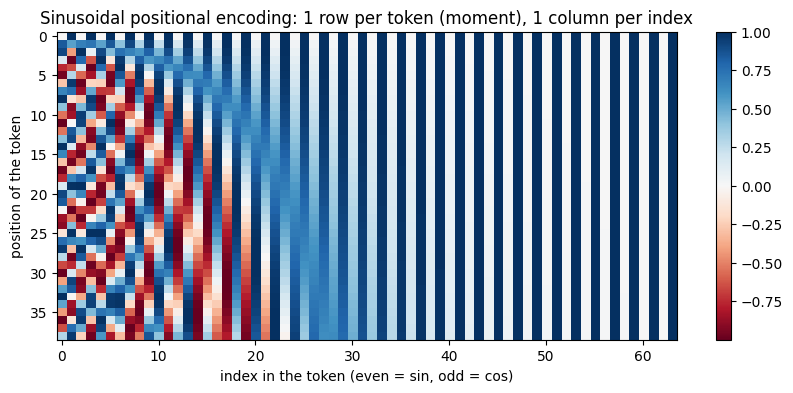

In [6]:
# ==================== The positional encoding of the course (sinusoidal) ====================
# The attention looks at all the tokens at the same time: without help it does not know which moment comes first.
# So we ADD to each token a vector that depends on its position:
#   PE(pos, 2k)     = sin(pos / 10000^(2k / d_model))     -> the even indexes get a sine
#   PE(pos, 2k + 1) = cos(pos / 10000^(2k / d_model))     -> the odd indexes get a cosine
# The first indexes change fast with the position, the last ones slowly: every position gets a different "code".
N_TOKENS = 39      # the number of moments after the CNN front-end (157 moments / 2 / 2 = 39)
D_MODEL = 64       # the size of each token


def positional_encoding(n_positions, d_model):
    pe = np.zeros((n_positions, d_model), dtype="float32")
    for pos in range(n_positions):
        for i in range(0, d_model, 2):                       # i = 0, 2, 4, ... (= 2k)
            angle = pos / (10000 ** (i / d_model))
            pe[pos, i] = np.sin(angle)                       # even index -> sin
            pe[pos, i + 1] = np.cos(angle)                   # odd index -> cos
    return pe


pe = positional_encoding(N_TOKENS, D_MODEL)
plt.figure(figsize=(10, 4))
plt.imshow(pe, aspect="auto", cmap="RdBu")
plt.colorbar()
plt.title("Sinusoidal positional encoding: 1 row per token (moment), 1 column per index")
plt.xlabel("index in the token (even = sin, odd = cos)")
plt.ylabel("position of the token")
plt.show()

In [7]:
# ==================== The Transformer encoder block (chapter 10) ====================
# 1. Multi-head self-attention: each token makes a query Q, a key K and a value V (3 Dense layers).
#    attention(Q, K, V) = softmax(Q.K^T / sqrt(key_dim)) . V  -> each token becomes a mix of the tokens it "looks at".
#    4 heads: d_model = 64 is split in 4 heads of key_dim = 16, each head learns its own way to look,
#    then the 4 results are concatenated and a last Dense layer (the projection) brings them back to 64.
# 2. Add & Norm: x + attention(x) (the residual connection), then LayerNormalization
# 3. Feed-forward network, on each token alone: Dense 128 + ReLU, then Dense 64
# 4. Add & Norm again
def transformer_block(x):
    attention = MultiHeadAttention(num_heads=4, key_dim=16, dropout=0.1)(x, x)    # query = x, value (and key) = x
    x = LayerNormalization()(Add()([x, attention]))                             # Add & Norm
    ffn = Dense(128, activation="relu")(x)                                      # feed-forward network
    ffn = Dense(D_MODEL)(ffn)
    ffn = Dropout(0.1)(ffn)
    x = LayerNormalization()(Add()([x, ffn]))                                   # Add & Norm
    return x

In [8]:
# ==================== Our Transformer-CNN (Keras functional API) ====================
LEARNING_RATE = 0.0005    # 2 x smaller than TP7: the attention layers learn better with smaller steps


def build_transformer_cnn():
    inputs = Input(shape=(40, 157, 1))                    # 1 spectrogram: 40 Mel bands x 157 moments

    # 1. CNN front-end: the local patterns (like TP7). padding="same" keeps the size before the MaxPooling
    x = Conv2D(16, (3, 3), padding="same", activation="relu")(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)                           # -> 20 bands x 78 moments x 16 maps
    x = Conv2D(32, (3, 3), padding="same", activation="relu")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)                           # -> 10 bands x 39 moments x 32 maps

    # 2. from feature maps to a sequence of tokens: 1 token per moment (the time axis comes first)
    x = Permute((2, 1, 3))(x)                             # -> 39 moments x 10 bands x 32 maps
    x = Reshape((N_TOKENS, 10 * 32))(x)                   # -> 39 tokens of 320 numbers
    x = Dense(D_MODEL)(x)                                 # -> 39 tokens of 64 numbers (the "embedding")

    # 3. + the positional encoding (the same for every wav: a constant of the model)
    x = x + pe[np.newaxis]

    # 4. 2 Transformer encoder blocks (encoder only: we classify, we do not generate text)
    x = transformer_block(x)
    x = transformer_block(x)

    # 5. the mean of the 39 tokens -> the decision
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(1, activation="sigmoid")(x)           # the probability that the heart is abnormal

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_transformer_cnn().summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 40, 157,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 40, 157,   │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 40, 157,   │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 20, 78,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 20, 78,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 20, 78,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 10, 39,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 39, 10,    │          0 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 39, 320)   │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 39, 64)    │     20,544 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 39, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 39, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 39, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 39, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 39, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 39, 64)    │      8,256 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 39, 64)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 39, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39, 64)    │        128 │ add_2[0][0]     

 Total params: 92,545 (361.50 KB)

 Trainable params: 92,449 (361.13 KB)

 Non-trainable params: 96 (384.00 B)

In [9]:
# ==================== The plots of the notebook ====================
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of wavs of class i (true) that the model put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    # ROC curve: for every threshold, the % of sick hearts found (true positive rate = recall) against the % of
    # normal hearts called abnormal (false positive rate). AUC = the area under it (1 = perfect, 0.5 = random)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")
    return area


def plot_fold(history, y_true, y_prob, fold):
    # like plot_acc_loss(): accuracy and loss per epoch (train vs validation) + confusion matrix + ROC of the fold
    plt.figure(figsize=(22, 4.5))
    plt.subplot(1, 4, 1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="validation")
    plt.title("Fold " + str(fold) + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validation")
    plt.title("Fold " + str(fold) + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 4, 3)
    PlotConfusionMatrix(confusion_matrix(y_true, (y_prob > 0.5).astype(int)), "Fold " + str(fold) + " - validation")
    plt.subplot(1, 4, 4)
    plot_roc(y_true, y_prob, "Fold " + str(fold) + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp9_transformer_val_fold" + str(fold) + ".png")
    plt.show()

class_weight: {0: np.float64(0.6447656592203241), 1: np.float64(2.226928895612708)}
==================== Fold 1


trained in 1.4 min


              precision    recall  f1-score   support

      normal       0.88      0.95      0.92       756
    abnormal       0.78      0.58      0.67       226

    accuracy                           0.87       982
   macro avg       0.83      0.77      0.79       982
weighted avg       0.86      0.87      0.86       982



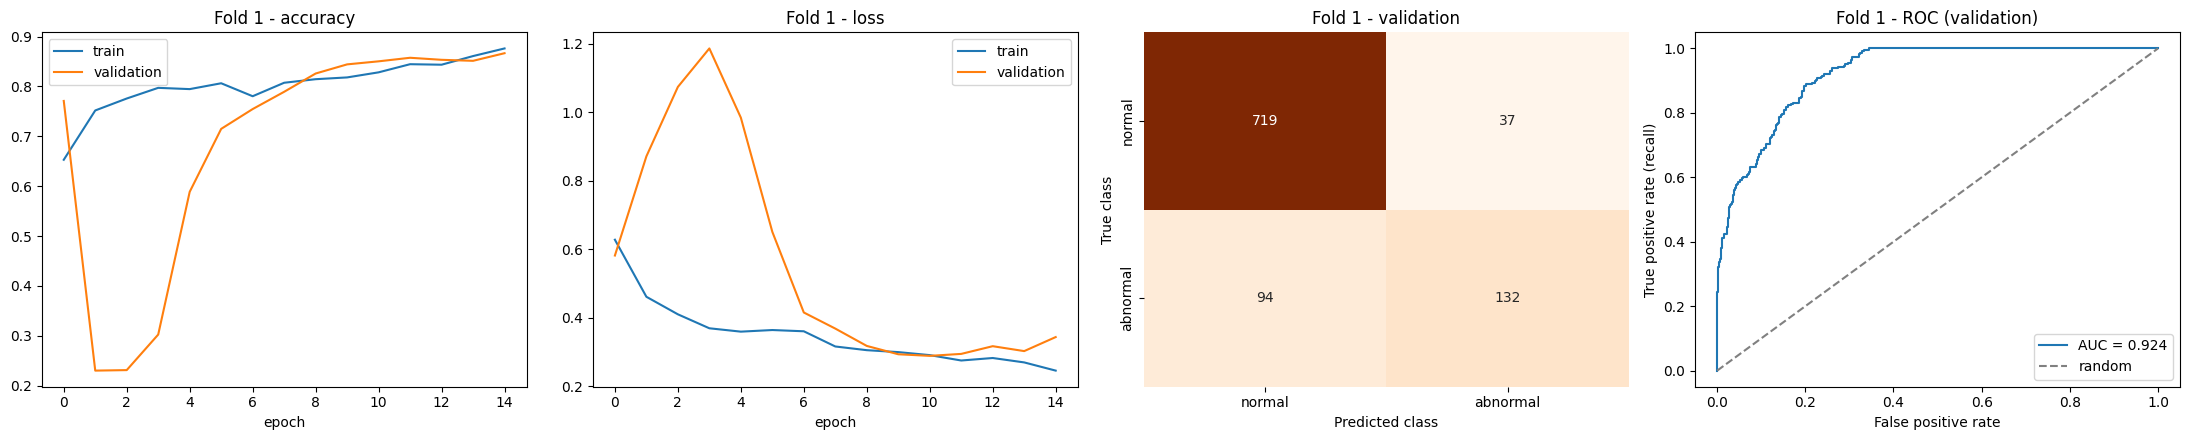

==================== Fold 2


trained in 1.3 min


              precision    recall  f1-score   support

      normal       0.99      0.69      0.81       759
    abnormal       0.47      0.97      0.64       222

    accuracy                           0.75       981
   macro avg       0.73      0.83      0.72       981
weighted avg       0.87      0.75      0.77       981



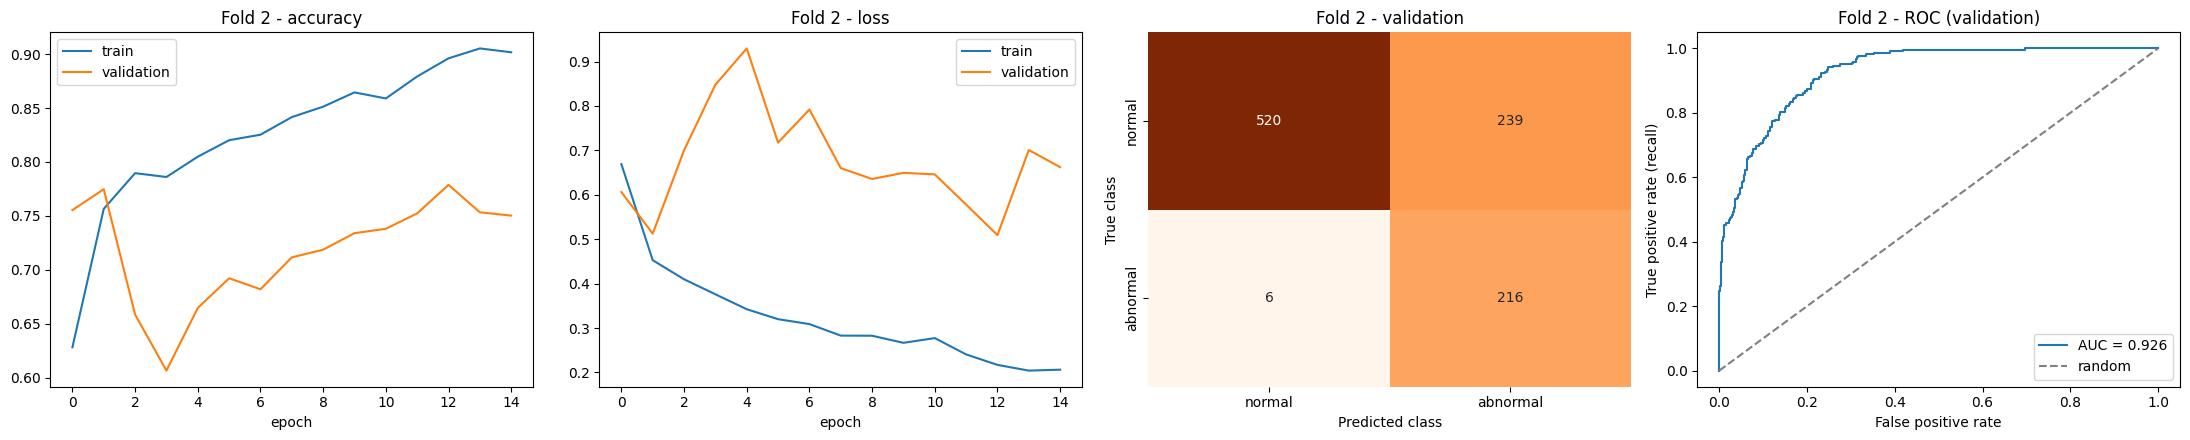

==================== Fold 3


trained in 1.4 min


              precision    recall  f1-score   support

      normal       0.96      0.79      0.87       768
    abnormal       0.54      0.89      0.67       213

    accuracy                           0.81       981
   macro avg       0.75      0.84      0.77       981
weighted avg       0.87      0.81      0.82       981



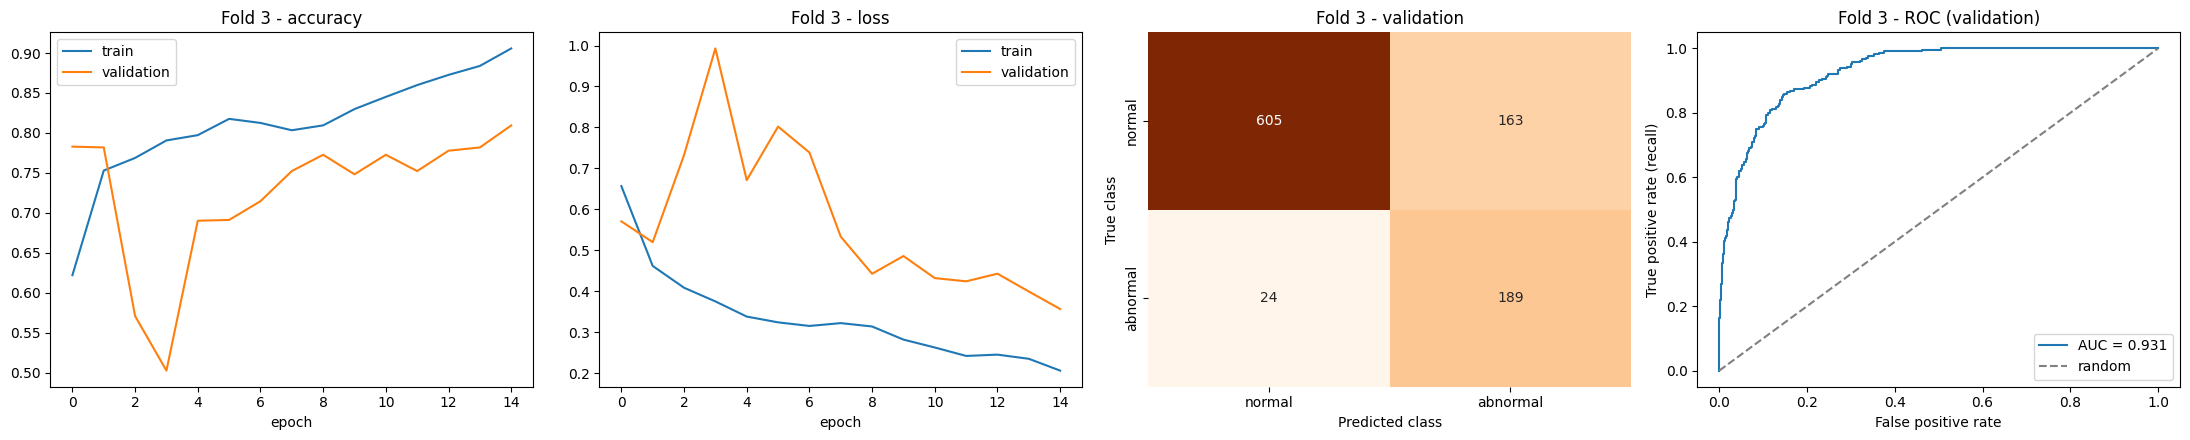

In [10]:
# ==================== VALIDATION: 3 folds on the 80% train part (the same folds as all the models) ====================
# EPOCHS = 15: a first run with 30 epochs showed that the validation loss of the 3 folds is the lowest around epoch
# 10-15 and goes up after (overfitting: the train loss keeps going down). So we keep 15 epochs.
# This choice uses only the VALIDATION curves (the 3 folds of the train part), never the test wavs.
EPOCHS = 15
BATCH_SIZE = 32
class_weight = {0: len(y_train) / (2 * np.sum(y_train == 0)), 1: len(y_train) / (2 * np.sum(y_train == 1))}
print("class_weight:", class_weight)

kfold = KFold(n_splits=3, shuffle=True, random_state=1)
results = []
histories = []
oof_prob = np.zeros(len(y_train))               # the "out-of-fold" probability of each train wav (for notebook 08)
oof_fold = np.zeros(len(y_train), dtype=int)    # the fold where the wav was in validation
fold = 1
for train_index, val_index in kfold.split(X_train):
    print("==================== Fold", fold)
    X_tr, X_val = X_train[train_index], X_train[val_index]
    y_tr, y_val = y_train[train_index], y_train[val_index]

    keras.utils.set_random_seed(0)    # the same random start each time -> the same results if we run it again
    model = build_transformer_cnn()
    start = time.time()
    history = model.fit(X_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                        validation_data=(X_val, y_val), verbose=0)
    print("trained in {:.1f} min".format((time.time() - start) / 60))

    y_prob = model.predict(X_val, verbose=0).ravel()
    y_pred = (y_prob > 0.5).astype(int)
    oof_prob[val_index] = y_prob
    oof_fold[val_index] = fold
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_val, y_prob)
    print(classification_report(y_val, y_pred, target_names=["normal", "abnormal"]))
    results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
        "auc": auc(false_positive_rate, true_positive_rate),
        "y_val": y_val,
        "y_prob": y_prob,
    })
    plot_fold(history, y_val, y_prob, fold)
    histories.append(history)
    fold = fold + 1

   fold  accuracy  precision  recall     f1    auc
0     1     0.867      0.781   0.584  0.668  0.924
1     2     0.750      0.475   0.973  0.638  0.926
2     3     0.809      0.537   0.887  0.669  0.931

Mean of the 3 folds (validation):
accuracy     0.809
precision    0.598
recall       0.815
f1           0.658
auc          0.927
dtype: float64


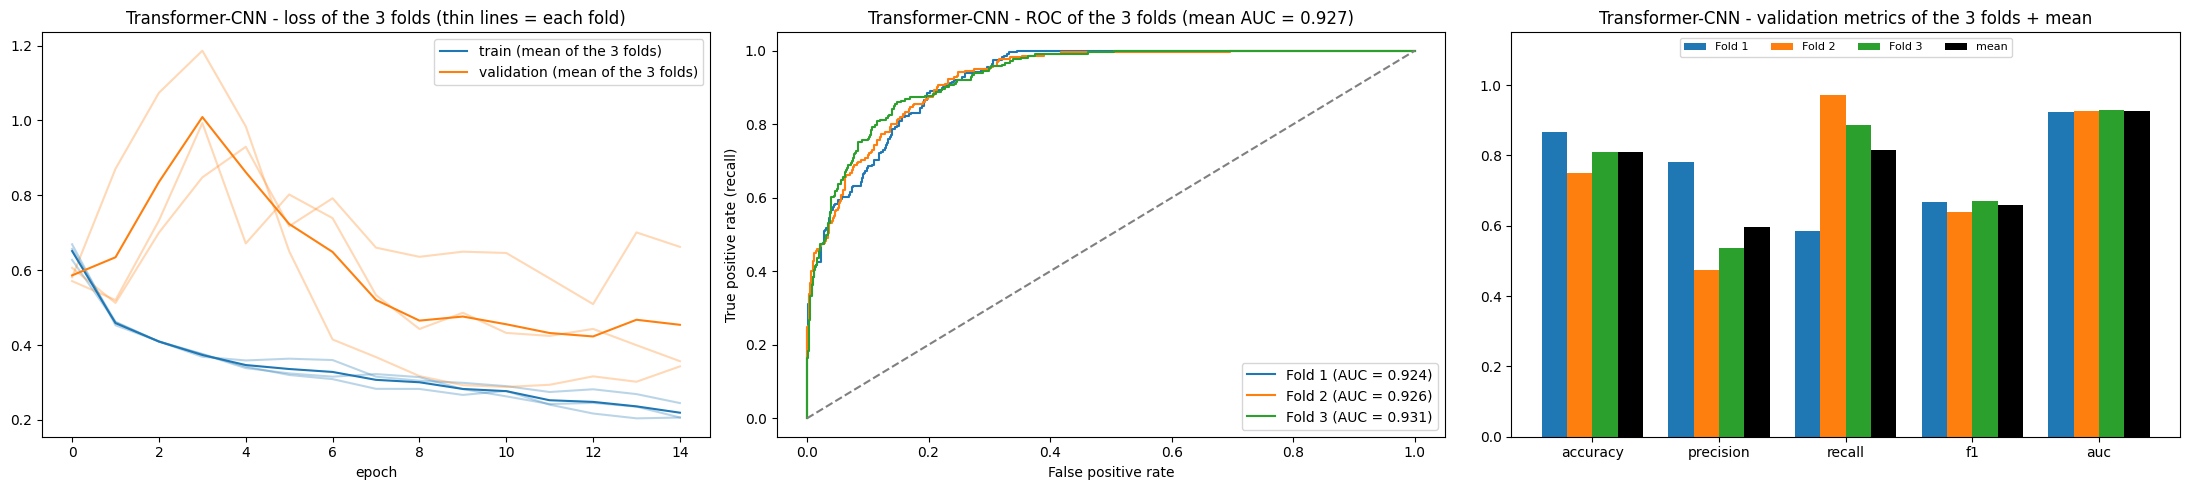

In [11]:
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
table = pd.DataFrame(results)[["fold"] + metrics]
print(table.round(3))
print()
print("Mean of the 3 folds (validation):")
print(table[metrics].mean().round(3))

# ONE summary figure of the validation: the loss curves of the 3 folds, their ROC curves, their metrics + the mean
plt.figure(figsize=(22, 5))
plt.subplot(1, 3, 1)
for h in histories:    # thin lines: each fold
    plt.plot(h.history["loss"], color="tab:blue", alpha=0.3)
    plt.plot(h.history["val_loss"], color="tab:orange", alpha=0.3)
plt.plot(np.mean([h.history["loss"] for h in histories], axis=0), color="tab:blue", label="train (mean of the 3 folds)")
plt.plot(np.mean([h.history["val_loss"] for h in histories], axis=0), color="tab:orange",
         label="validation (mean of the 3 folds)")
plt.title("Transformer-CNN - loss of the 3 folds (thin lines = each fold)")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 3, 2)
for r in results:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(r["y_val"], r["y_prob"])
    plt.plot(false_positive_rate, true_positive_rate, label="Fold " + str(r["fold"]) + " (AUC = {:.3f})".format(r["auc"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("Transformer-CNN - ROC of the 3 folds (mean AUC = {:.3f})".format(table["auc"].mean()))
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")

plt.subplot(1, 3, 3)
x = np.arange(len(metrics))
for i in range(3):
    plt.bar(x - 0.3 + 0.2 * i, table.loc[i, metrics], width=0.2, label="Fold " + str(i + 1))
plt.bar(x + 0.3, table[metrics].mean(), width=0.2, color="black", label="mean")
plt.xticks(x, metrics)
plt.ylim(0, 1.15)
plt.title("Transformer-CNN - validation metrics of the 3 folds + mean")
plt.legend(loc="upper center", ncol=4, fontsize=8)

plt.tight_layout()
plt.savefig(plots_folder + "tp9_transformer_val_summary.png")
plt.show()

final Transformer-CNN trained on 2944 wavs (the 80% train part)


              precision    recall  f1-score   support

      normal       0.95      0.81      0.88       572
    abnormal       0.57      0.86      0.68       165

    accuracy                           0.82       737
   macro avg       0.76      0.84      0.78       737
weighted avg       0.87      0.82      0.83       737



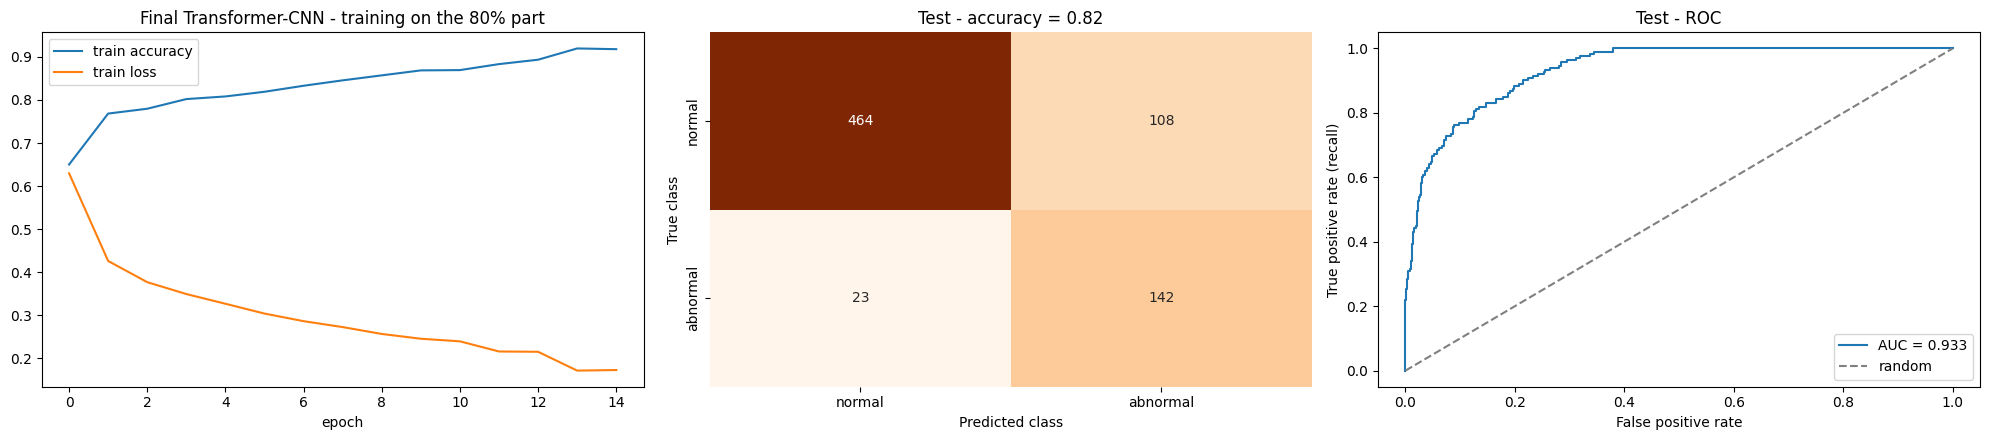

In [12]:
# ==================== TEST: the final model learns on the whole 80% part, then is tested ONCE on the 20% ====================
keras.utils.set_random_seed(0)
final_model = build_transformer_cnn()
final_history = final_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                                verbose=0)
print("final Transformer-CNN trained on", len(y_train), "wavs (the 80% train part)")

y_test_prob = final_model.predict(X_test, verbose=0).ravel()
y_test_pred = (y_test_prob > 0.5).astype(int)
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_test_prob)
test_results = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
    "auc": auc(false_positive_rate, true_positive_rate),
}
report = classification_report(y_test, y_test_pred, target_names=["normal", "abnormal"])
print(report)
with open(plots_folder + "tp9_transformer_test_report.txt", "w") as f:
    f.write("Transformer-CNN - test set (" + str(len(y_test)) + " wavs never seen)\n\n" + report)

plt.figure(figsize=(20, 4.5))
plt.subplot(1, 3, 1)
plt.plot(final_history.history["accuracy"], label="train accuracy")
plt.plot(final_history.history["loss"], label="train loss")
plt.title("Final Transformer-CNN - training on the 80% part")
plt.xlabel("epoch")
plt.legend()
plt.subplot(1, 3, 2)
PlotConfusionMatrix(confusion_matrix(y_test, y_test_pred), "Test - accuracy = {:.2f}".format(test_results["accuracy"]))
plt.subplot(1, 3, 3)
plot_roc(y_test, y_test_prob, "Test - ROC")
plt.tight_layout()
plt.savefig(plots_folder + "tp9_transformer_test.png")
plt.show()

# the probabilities of this model, for the ensemble (notebook 08): out-of-fold (validation) + test
with open(project_folder + "probs_transformercnn.data", "wb") as f:
    pickle.dump({"model": "TransformerCNN", "train_names": list(files[~is_test]), "train_y": list(y_train),
                 "fold": list(oof_fold), "oof_prob": list(oof_prob), "test_names": list(files[is_test]),
                 "test_y": list(y_test), "test_prob": list(y_test_prob)}, f)

In [13]:
# ==================== MLflow (Service 6) ====================
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")

with mlflow.start_run(run_name="transformer_cnn"):
    mlflow.log_param("model", "TransformerCNN")
    mlflow.log_param("features", "mel spectrogram 40 x 157 (5 s, 2000 Hz)")
    mlflow.log_param("layers", "2 x (Conv2D + BatchNorm + MaxPooling) + Dense 64 + positional encoding "
                               "+ 2 Transformer blocks + GlobalAveragePooling1D + Dropout 0.3 + Dense 1")
    mlflow.log_param("n_tokens", N_TOKENS)
    mlflow.log_param("d_model", D_MODEL)
    mlflow.log_param("num_heads", 4)
    mlflow.log_param("key_dim", 16)
    mlflow.log_param("ffn_units", 128)
    mlflow.log_param("n_blocks", 2)
    mlflow.log_param("dropout", 0.1)
    mlflow.log_param("optimizer", "adam")
    mlflow.log_param("learning_rate", LEARNING_RATE)
    mlflow.log_param("epochs", EPOCHS)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("n_folds", 3)
    mlflow.log_param("protocol", "3 folds on the 80% train part (validation), final model on the 80%, tested on the 20%")
    mlflow.log_param("n_train", len(y_train))
    mlflow.log_param("n_test", len(y_test))

    for metric in metrics:
        mlflow.log_metric("mean_" + metric, table[metric].mean())
        mlflow.log_metric("test_" + metric, test_results[metric])
    for r in results:
        for metric in metrics:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp9_transformer_val_fold" + str(fold) + ".png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp9_transformer_val_summary.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp9_transformer_test.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp9_transformer_test_report.txt", artifact_path="plots/test")

    mlflow.keras.log_model(final_model, "model")    # the final model (the tested one: exported to ONNX by notebook 05)

    for r in results:
        fold = r["fold"]
        h = histories[fold - 1].history
        with mlflow.start_run(run_name="transformer_cnn_fold" + str(fold), nested=True):
            mlflow.log_param("fold", fold)
            for epoch in range(EPOCHS):
                mlflow.log_metric("train_loss", h["loss"][epoch], step=epoch + 1)
                mlflow.log_metric("val_loss", h["val_loss"][epoch], step=epoch + 1)
                mlflow.log_metric("train_accuracy", h["accuracy"][epoch], step=epoch + 1)
                mlflow.log_metric("val_accuracy", h["val_accuracy"][epoch], step=epoch + 1)
            mlflow.log_metric("val_precision", r["precision"])
            mlflow.log_metric("val_recall", r["recall"])
            mlflow.log_metric("val_f1", r["f1"])
            mlflow.log_metric("val_auc", r["auc"])
            mlflow.log_artifact(plots_folder + "tp9_transformer_val_fold" + str(fold) + ".png",
                                artifact_path="plots/validation")
print("Transformer-CNN saved in MLflow")

2026/11/27 11:35:41 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/27 11:38:38 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\farah\AppData\Local\Temp\tmpgfx9g4dw\model, flavor: keras). Fall back to return ['keras==3.12.4']. Set logging level to DEBUG to see the full traceback. 


2026/11/27 11:38:38 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run transformer_cnn_fold1 at: http://localhost:5000/#/experiments/2/runs/923656b0509e4186b18ef16575e4b319
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run transformer_cnn_fold2 at: http://localhost:5000/#/experiments/2/runs/80b26667e7e04ca080fd1c5660e48da5
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run transformer_cnn_fold3 at: http://localhost:5000/#/experiments/2/runs/0478f864e3fb4a60a2c2b138b2bc8137
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run transformer_cnn at: http://localhost:5000/#/experiments/2/runs/da3bc84996f54efd8e61960772119cbb
🧪 View experiment at: http://localhost:5000/#/experiments/2


Transformer-CNN saved in MLflow
